# Classificação de Nível de Obesidade

Tratamento dos dados, base do dashboard, pipeline de Machine Learning e exportação do modelo usado no app do Streamlit.

# 0. Importando as bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [2]:
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score, accuracy_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline  # aplica o SMOTE só no treino (no fit), nunca na previsão

# Transformadores próprios, em módulo separado para o app do Streamlit carregar o modelo salvo
from transformadores import OneHotEncodingNames, OrdinalFeature, MinMax, ORDEM_CLASSES

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [4]:
import warnings
warnings.filterwarnings('ignore')

# 1. Tratamento dos dados

In [5]:
# Subindo os dados
dados = pd.read_csv('data/Obesity.csv')

In [6]:
dados.head(3)

,Gender,Age,Height,Weight,family_history,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,Obesity
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight


In [7]:
# Checando por valores nulos
dados.isnull().sum()

Gender            0
Age               0
Height            0
Weight            0
family_history    0
FAVC              0
FCVC              0
NCP               0
CAEC              0
SMOKE             0
CH2O              0
SCC               0
FAF               0
TUE               0
CALC              0
MTRANS            0
Obesity           0
dtype: int64

In [8]:
# Checando por duplicatas
dados.duplicated().sum()

np.int64(24)

In [9]:
# Removendo duplicatas
dados.drop_duplicates(inplace=True)

In [10]:
# Obtendo informações gerais sobre o dataset
dados.shape

(2087, 17)

In [11]:
dados.info()

<class 'pandas.DataFrame'>
Index: 2087 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Gender          2087 non-null   str    
 1   Age             2087 non-null   float64
 2   Height          2087 non-null   float64
 3   Weight          2087 non-null   float64
 4   family_history  2087 non-null   str    
 5   FAVC            2087 non-null   str    
 6   FCVC            2087 non-null   float64
 7   NCP             2087 non-null   float64
 8   CAEC            2087 non-null   str    
 9   SMOKE           2087 non-null   str    
 10  CH2O            2087 non-null   float64
 11  SCC             2087 non-null   str    
 12  FAF             2087 non-null   float64
 13  TUE             2087 non-null   float64
 14  CALC            2087 non-null   str    
 15  MTRANS          2087 non-null   str    
 16  Obesity         2087 non-null   str    
dtypes: float64(8), str(9)
memory usage: 428.0 KB


## 1.1 Arredondando números que deveriam ser inteiros

In [12]:
dados['FCVC'] = dados['FCVC'].round(0)

In [13]:
dados['NCP'] = dados['NCP'].round(0)

In [14]:
dados['CH2O'] = dados['CH2O'].round(0)

In [15]:
dados['FAF'] = dados['FAF'].round(0)

In [16]:
dados['TUE'] = dados['TUE'].round(0)

# 2. Análise Exploratória de Dados

In [17]:
# Obtendo informações avançadas sobre o dataset
dados.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000
mean,24.353090,1.702674,86.858730,2.425970,2.703402,2.011500,1.009104,0.669861
std,6.368801,0.093186,26.190847,0.585177,0.797108,0.685322,0.898712,0.673970
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.915937,1.630178,66.000000,2.000000,3.000000,2.000000,0.000000,0.000000
50%,22.847618,1.701584,83.101100,2.000000,3.000000,2.000000,1.000000,1.000000
75%,26.000000,1.769491,108.015907,3.000000,3.000000,2.000000,2.000000,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


In [18]:
dados.columns

Index(['Gender', 'Age', 'Height', 'Weight', 'family_history', 'FAVC', 'FCVC',
       'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS',
       'Obesity'],
      dtype='str')

## 2.1 Entendendo os valores únicos

In [19]:
dados['Gender'].unique()

<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

In [20]:
dados['Age'].unique()

array([21.      , 23.      , 27.      , ..., 22.524036, 24.361936,
       23.664709], shape=(1402,))

In [21]:
dados['Height'].unique()

array([1.62    , 1.52    , 1.8     , ..., 1.752206, 1.73945 , 1.738836],
      shape=(1574,))

In [22]:
dados['Weight'].unique()

array([ 64.      ,  56.      ,  77.      , ..., 133.689352, 133.346641,
       133.472641], shape=(1525,))

In [23]:
dados['family_history'].unique()

<ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str

In [24]:
dados['FAVC'].unique()

<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str

In [25]:
dados['FCVC'].unique()

array([2., 3., 1.])

In [26]:
dados['NCP'].unique()

array([3., 1., 4., 2.])

In [27]:
dados['CAEC'].unique()

<ArrowStringArray>
['Sometimes', 'Frequently', 'Always', 'no']
Length: 4, dtype: str

In [28]:
dados['SMOKE'].unique()

<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str

In [29]:
dados['CH2O'].unique()

array([2., 3., 1.])

In [30]:
dados['SCC'].unique()

<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str

In [31]:
dados['FAF'].unique()

array([0., 3., 2., 1.])

In [32]:
dados['TUE'].unique()

array([1., 0., 2.])

In [33]:
dados['CALC'].unique()

<ArrowStringArray>
['no', 'Sometimes', 'Frequently', 'Always']
Length: 4, dtype: str

In [34]:
dados['MTRANS'].unique()

<ArrowStringArray>
['Public_Transportation', 'Walking', 'Automobile', 'Motorbike', 'Bike']
Length: 5, dtype: str

In [35]:
dados['Obesity'].unique()

<ArrowStringArray>
[      'Normal_Weight',  'Overweight_Level_I', 'Overweight_Level_II',
      'Obesity_Type_I', 'Insufficient_Weight',     'Obesity_Type_II',
    'Obesity_Type_III']
Length: 7, dtype: str

## 2.2 Análise visual com Boxplots

<Axes: xlabel='Age'>

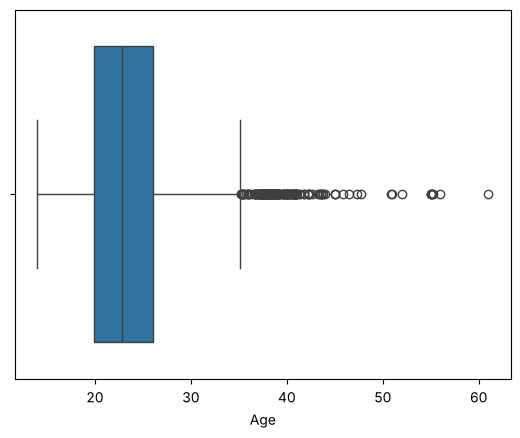

In [36]:
sns.boxplot(data=dados, x='Age')

<Axes: xlabel='Height'>

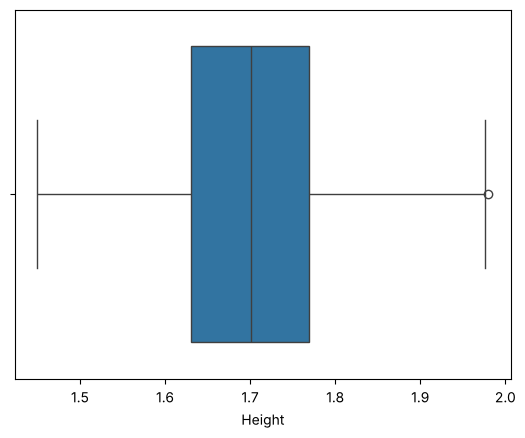

In [37]:
sns.boxplot(data=dados, x='Height')

<Axes: xlabel='Weight'>

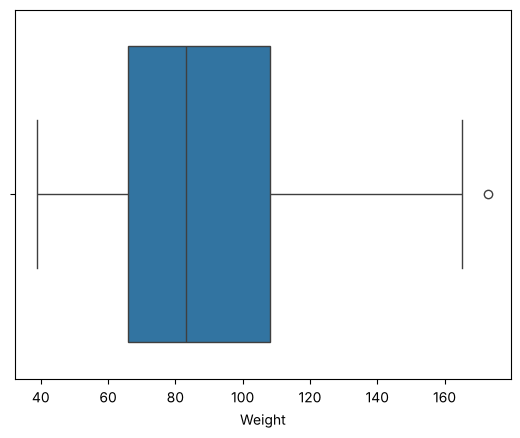

In [38]:
sns.boxplot(data=dados, x='Weight')

## 2.3 Análise das distribuições categóricas

In [39]:
def distribuicao (coluna):
  contagem = dados[coluna].value_counts()
  percentual = dados[coluna].value_counts(normalize=True)*100
  df = pd.DataFrame({
    'Contagem': contagem,
    'Percentual (%)': percentual
  })
  return df

In [40]:
distribuicao('Gender')

,Contagem,Percentual (%)
Gender,,
Male,1052,50.407283
Female,1035,49.592717


In [41]:
distribuicao('family_history')

,Contagem,Percentual (%)
family_history,,
yes,1722,82.510781
no,365,17.489219


In [42]:
distribuicao('FAVC')

,Contagem,Percentual (%)
FAVC,,
yes,1844,88.356493
no,243,11.643507


In [43]:
distribuicao('FCVC')

,Contagem,Percentual (%)
FCVC,,
2.0,994,47.628174
3.0,991,47.484427
1.0,102,4.887398


In [44]:
distribuicao('NCP')

,Contagem,Percentual (%)
NCP,,
3.0,1466,70.244370
1.0,296,14.183038
2.0,176,8.433158
4.0,149,7.139435


In [45]:
distribuicao('CAEC')

,Contagem,Percentual (%)
CAEC,,
Sometimes,1761,84.379492
Frequently,236,11.308098
Always,53,2.539530
no,37,1.772880


In [46]:
distribuicao('SMOKE')

,Contagem,Percentual (%)
SMOKE,,
no,2043,97.891711
yes,44,2.108289


In [47]:
distribuicao('CH2O')

,Contagem,Percentual (%)
CH2O,,
2.0,1107,53.042645
3.0,502,24.053666
1.0,478,22.903690


In [48]:
distribuicao('SCC')

,Contagem,Percentual (%)
SCC,,
no,1991,95.400096
yes,96,4.599904


In [49]:
distribuicao('FAF')

,Contagem,Percentual (%)
FAF,,
1.0,759,36.367992
0.0,714,34.211787
2.0,495,23.718256
3.0,119,5.701965


In [50]:
distribuicao('TUE')

,Contagem,Percentual (%)
TUE,,
0.0,932,44.657403
1.0,912,43.699090
2.0,243,11.643507


In [51]:
distribuicao('CALC')

,Contagem,Percentual (%)
CALC,,
Sometimes,1380,66.123622
no,636,30.474365
Frequently,70,3.354097
Always,1,0.047916


In [52]:
distribuicao('MTRANS')

,Contagem,Percentual (%)
MTRANS,,
Public_Transportation,1558,74.652611
Automobile,456,21.849545
Walking,55,2.635362
Motorbike,11,0.527072
Bike,7,0.335410


In [53]:
distribuicao('Obesity')

,Contagem,Percentual (%)
Obesity,,
Obesity_Type_I,351,16.818400
Obesity_Type_III,324,15.524677
Obesity_Type_II,297,14.230954
Overweight_Level_II,290,13.895544
Normal_Weight,282,13.512218
Overweight_Level_I,276,13.224724
Insufficient_Weight,267,12.793483


## 2.4 Análise visual com Histogramas

<Axes: xlabel='Age', ylabel='Count'>

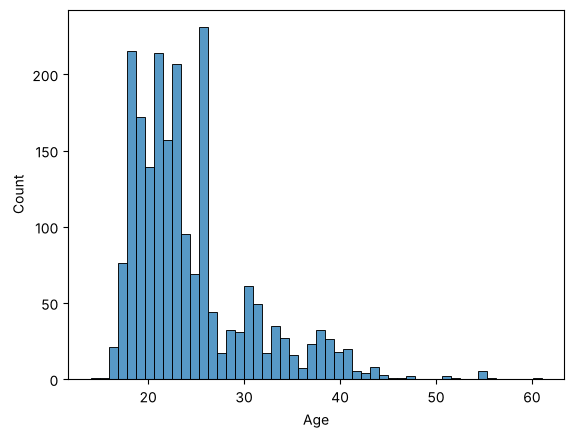

In [54]:
sns.histplot(data=dados, x='Age')

<Axes: xlabel='Height', ylabel='Count'>

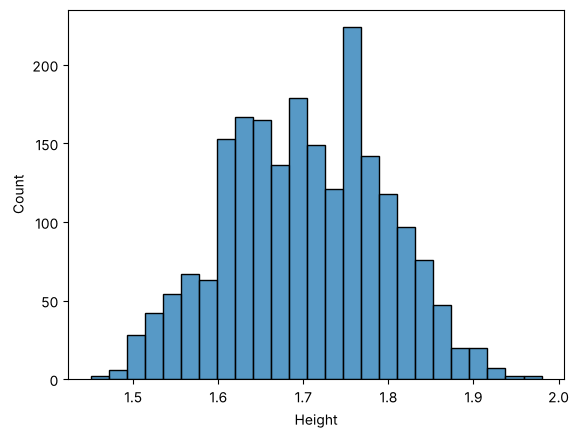

In [55]:
sns.histplot(data=dados, x='Height')

<Axes: xlabel='Weight', ylabel='Count'>

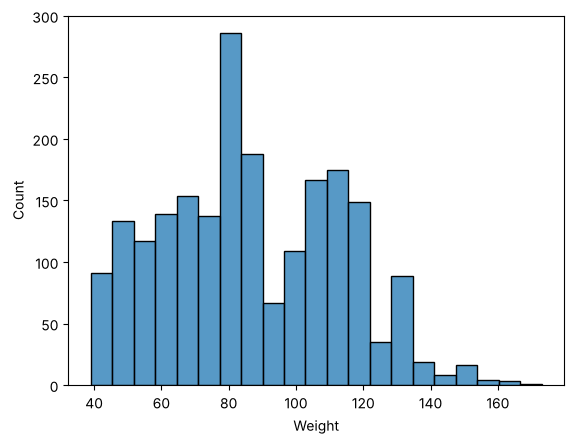

In [56]:
sns.histplot(data=dados, x='Weight')

# 3. Formatação do dataset para uso no Dashboard

In [57]:
dash = dados.copy()

In [58]:
dash.head()

,Gender,Age,Height,Weight,family_history,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,Obesity
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [59]:
map_gender = {'Female': 'Feminino', 'Male': 'Masculino'}
map_family = {'yes': 'Sim', 'no': 'Não'}
map_favc = {'yes': 'Sim', 'no': 'Não'}
map_fcvc = {1:'Raramente', 2:'Às Vezes', 3:'Sempre'}
map_ncp = {1:'Uma', 2:'Duas', 3:'Três', 4:'Quatro ou mais' }
map_caec = {'no': 'Não', 'Sometimes': 'Às Vezes', 'Frequently':'Frequentemente', 'Always':'Sempre'}
map_smoke = {'yes': 'Sim', 'no': 'Não'}
map_ch20 = {1:'<1 L/dia', 2:'1-2 L/dia', 3:'> 2 L/dia'}
map_scc = {'yes': 'Sim', 'no': 'Não'}
map_faf = {0:'Nenhuma', 1:'1-2x/semana', 2:'3-4x/semana', 3:'5-7x/semana'}
map_tue = {0:'0-2h/dia', 1:'3-5h/dia', 2:'mais que 5h/dia'}
map_calc = {'no':'Não Bebe', 'Sometimes': 'Às Vezes', 'Frequently':'Frequentemente', 'Always':'Sempre'}
map_mtrans = {'Automobile': 'Carro', 'Motorbike':'Moto', 'Bike':'Bicicleta',
              'Public_Transportation':'Transporte Público', 'Walking':'A pé'}
map_obesity = {'Insufficient_Weight': 'Abaixo do Peso', 'Normal_Weight':'Peso Normal',
               'Overweight_Level_I':'Sobrepeso I', 'Overweight_Level_II':'Sobrepeso II',
               'Obesity_Type_I':'Obesidade I', 'Obesity_Type_II':'Obesidade II',
               'Obesity_Type_III':'Obesidade III'}

In [60]:
dash = dash.assign(
    Gender=dash['Gender'].map(map_gender),
    family_history=dash['family_history'].map(map_family),
    FAVC=dash['FAVC'].map(map_favc),
    FCVC=dash['FCVC'].map(map_fcvc),
    NCP=dash['NCP'].map(map_ncp),
    CAEC=dash['CAEC'].map(map_caec),
    SMOKE=dash['SMOKE'].map(map_smoke),
    CH2O=dash['CH2O'].map(map_ch20),
    SCC=dash['SCC'].map(map_scc),
    FAF=dash['FAF'].map(map_faf),
    TUE=dash['TUE'].map(map_tue),
    CALC=dash['CALC'].map(map_calc),
    MTRANS=dash['MTRANS'].map(map_mtrans),
    Obesity=dash['Obesity'].map(map_obesity)
)

In [61]:
df_clean = dash.copy()
df_clean.to_csv('data/df_clean.csv', index=False)

In [62]:
titulos = ['Gênero', 'Idade', 'Altura', 'Peso', 'Histórico Familiar', 'Consumo de comidas calóricas',
           'Consumo de vegetais', 'Número de refeições', 'Come entre refeições?', 'Fuma?',
           'Consumo de água', 'Monitora calorias?', 'Atividade física',
           'Tempo em dispositivos eletrônicos', 'Consumo de álcool', 'Modal de transporte',
           'Nível de obesidade']

In [63]:
dash.columns = titulos

In [64]:
dash.to_csv('data/dash.csv', index=False)

# 4. Feature Engineering

## 4.1 Analisando correlações entre as variáveis

In [65]:
feature = dados.copy()

In [66]:
# Transformando valores em números para análise de correlação
map_gender = {'Female': 0, 'Male': 1}
map_family = {'yes': 1, 'no': 0}
map_favc = {'yes': 1, 'no': 0}
map_caec = {'no': 0, 'Sometimes': 1, 'Frequently':2, 'Always':3}
map_smoke = {'yes': 1, 'no': 0}
map_scc = {'yes': 1, 'no': 0}
map_calc = {'no':0, 'Sometimes': 1, 'Frequently':2, 'Always':3}
map_mtrans = {'Automobile': 1, 'Motorbike':2, 'Bike':3,
              'Public_Transportation':4, 'Walking':5}
map_obesity = {'Insufficient_Weight': 1, 'Normal_Weight':2, 'Overweight_Level_I':3,
               'Overweight_Level_II':4, 'Obesity_Type_I':5, 'Obesity_Type_II':6, 'Obesity_Type_III':7}

In [67]:
feature = feature.assign(
    Gender=feature['Gender'].map(map_gender),
    family_history=feature['family_history'].map(map_family),
    FAVC=feature['FAVC'].map(map_favc),
    CAEC=feature['CAEC'].map(map_caec),
    SMOKE=feature['SMOKE'].map(map_smoke),
    SCC=feature['SCC'].map(map_scc),
    CALC=feature['CALC'].map(map_calc),
    MTRANS=feature['MTRANS'].map(map_mtrans),
    Obesity=feature['Obesity'].map(map_obesity)
)

<Axes: >

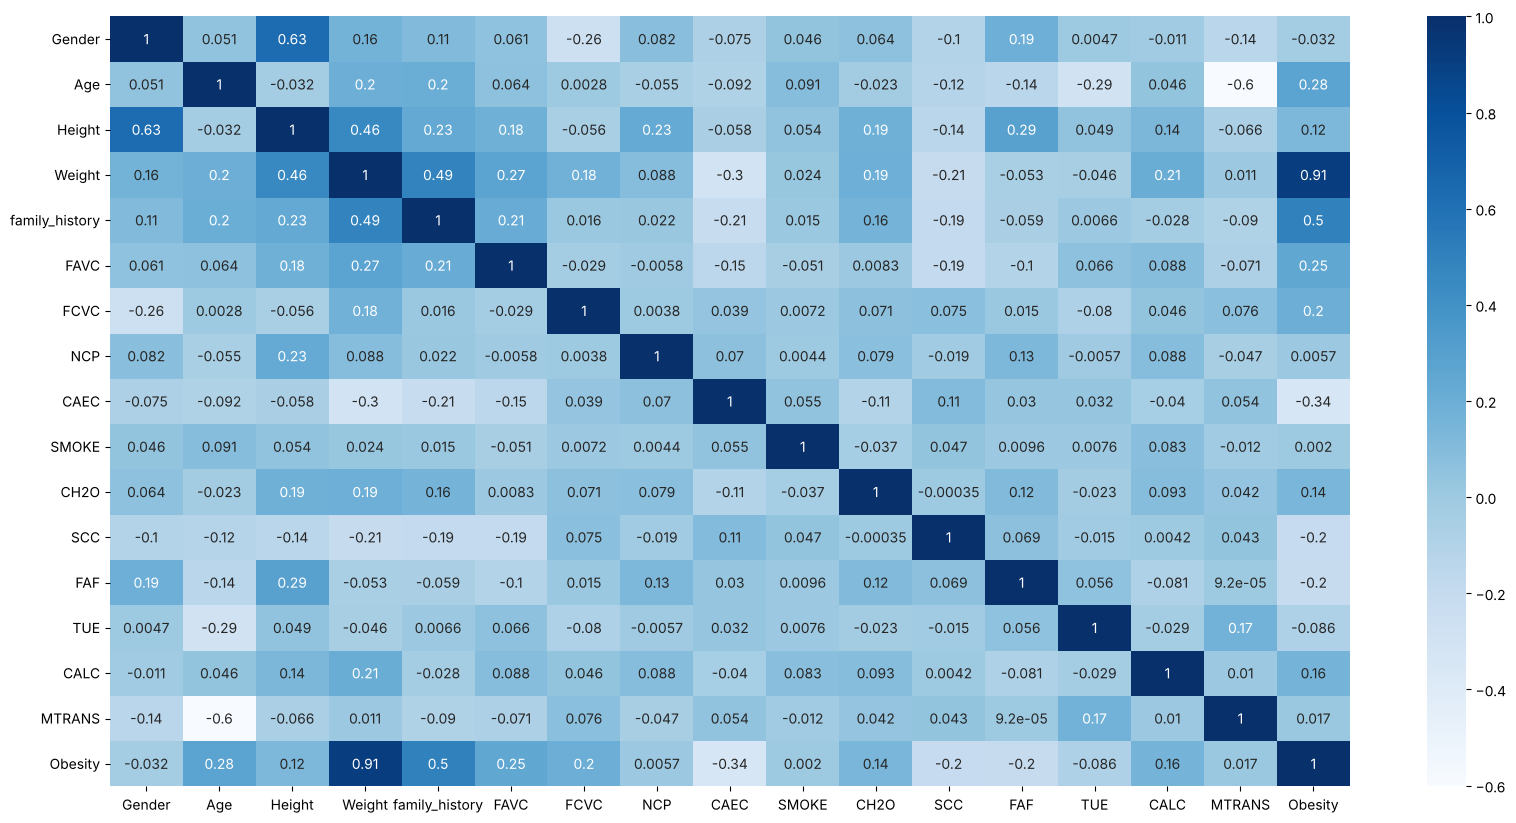

In [68]:
corr = feature.corr(numeric_only=True)
plt.figure(figsize = (20,10))
sns.heatmap(corr, cmap="Blues", annot=True)

## 4.2 Dividindo o dataset em treino e teste

A divisão é estratificada pelo alvo, para que treino e teste tenham a mesma proporção de cada nível de obesidade.

In [69]:
SEED = 1561651
train_df, test_df = train_test_split(df_clean, test_size=0.2, random_state=SEED, stratify=df_clean['Obesity'])

In [70]:
X_train, y_train = train_df.drop(columns='Obesity'), train_df['Obesity']
X_test, y_test = test_df.drop(columns='Obesity'), test_df['Obesity']
print(X_train.shape, X_test.shape)

(1669, 16) (418, 16)


# 5. Pipeline

Etapas: one-hot nas variáveis binárias e nominais, encoding ordinal com a ordem das categorias definida explicitamente, normalização MinMax nas numéricas e balanceamento das classes com SMOTE.

**Cuidados para não vazar informação do teste:**
- encoders e scaler são ajustados **só no treino** e apenas aplicados no teste;
- o SMOTE gera registros sintéticos **só no treino**; o teste mantém só dados reais;
- o alvo não passa pelos transformadores, então o mesmo pipeline serve para prever pacientes novos no app.

O `Pipeline` do imbalanced-learn faz isso automaticamente: o SMOTE roda no `fit` e é ignorado no `predict`.

In [71]:
def cria_pipeline(modelo, colunas_min_max=None):
    return Pipeline([
        ('one_hot', OneHotEncodingNames()),
        ('ordinal', OrdinalFeature()),
        ('min_max', MinMax(colunas_min_max)),
        ('smote', SMOTE(sampling_strategy='not majority', random_state=SEED)),
        ('modelo', modelo)
    ])

# 6. Modelos

## 6.1 Função de avaliação

In [72]:
def roda_modelo(modelo, X_train, X_test, y_train, y_test, colunas_min_max=None):
    pipe = cria_pipeline(modelo, colunas_min_max).fit(X_train, y_train)
    previsao = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)

    print(f"\n{'-'*30} Resultados {modelo.__class__.__name__} {'-'*30}\n")
    print(f"Acurácia: {accuracy_score(y_test, previsao):.4f}")
    print(f"AUC (macro, OVR): {roc_auc_score(y_test, prob, multi_class='ovr', labels=pipe.classes_):.4f}\n")

    fig, ax = plt.subplots(figsize=(8, 8))
    ConfusionMatrixDisplay.from_predictions(y_test, previsao, labels=ORDEM_CLASSES, ax=ax, cmap='Blues', xticks_rotation=45)
    plt.show()

    print(classification_report(y_test, previsao, labels=ORDEM_CLASSES))
    return pipe

## 6.2 Regressão Logística


------------------------------ Resultados LogisticRegression ------------------------------

Acurácia: 0.7081
AUC (macro, OVR): 0.9400



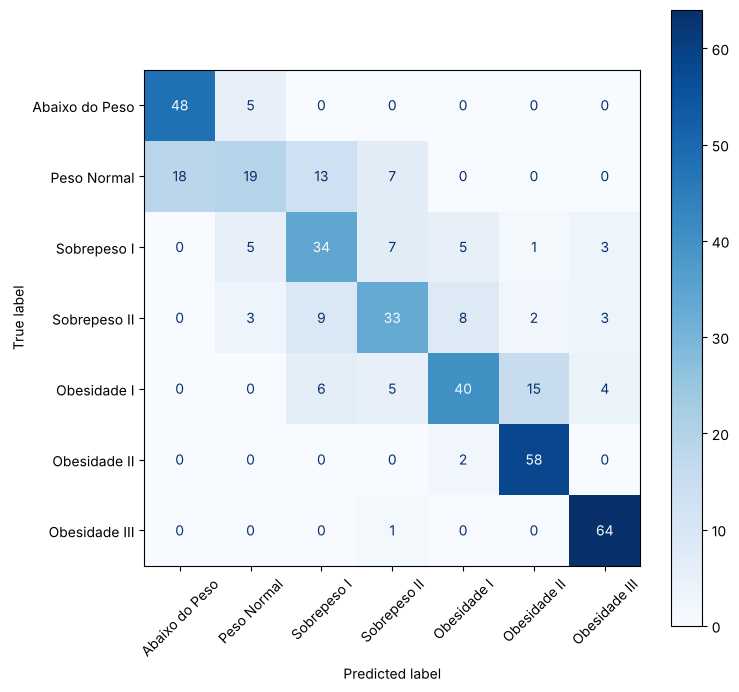

                precision    recall  f1-score   support

Abaixo do Peso       0.73      0.91      0.81        53
   Peso Normal       0.59      0.33      0.43        57
   Sobrepeso I       0.55      0.62      0.58        55
  Sobrepeso II       0.62      0.57      0.59        58
   Obesidade I       0.73      0.57      0.64        70
  Obesidade II       0.76      0.97      0.85        60
 Obesidade III       0.86      0.98      0.92        65

      accuracy                           0.71       418
     macro avg       0.69      0.71      0.69       418
  weighted avg       0.70      0.71      0.69       418



In [73]:
pipe_logistico = roda_modelo(LogisticRegression(max_iter=2000), X_train, X_test, y_train, y_test)

## 6.3 Árvore de Decisão


------------------------------ Resultados DecisionTreeClassifier ------------------------------

Acurácia: 0.9354
AUC (macro, OVR): 0.9618



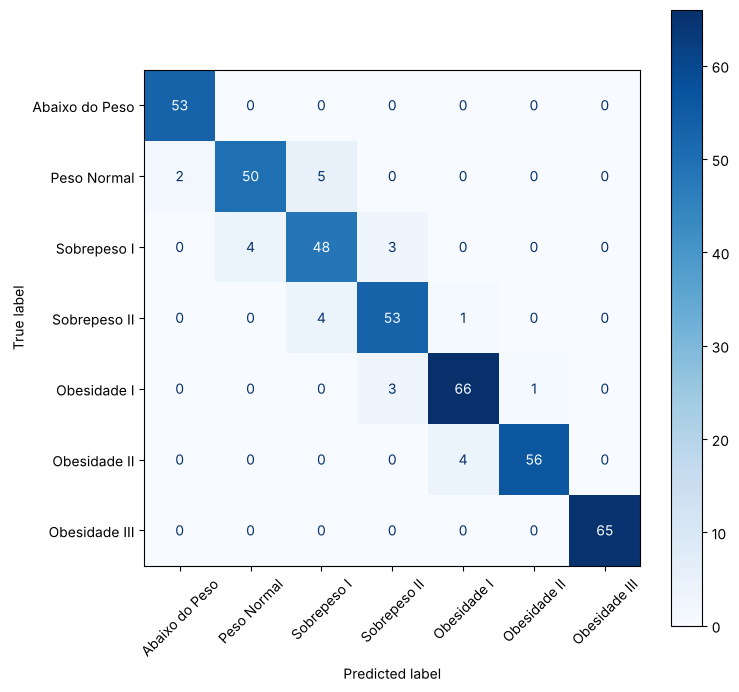

                precision    recall  f1-score   support

Abaixo do Peso       0.96      1.00      0.98        53
   Peso Normal       0.93      0.88      0.90        57
   Sobrepeso I       0.84      0.87      0.86        55
  Sobrepeso II       0.90      0.91      0.91        58
   Obesidade I       0.93      0.94      0.94        70
  Obesidade II       0.98      0.93      0.96        60
 Obesidade III       1.00      1.00      1.00        65

      accuracy                           0.94       418
     macro avg       0.93      0.93      0.93       418
  weighted avg       0.94      0.94      0.94       418



In [74]:
pipe_tree = roda_modelo(DecisionTreeClassifier(random_state=SEED), X_train, X_test, y_train, y_test)

## 6.4 Random Forest


------------------------------ Resultados RandomForestClassifier ------------------------------

Acurácia: 0.9498
AUC (macro, OVR): 0.9975



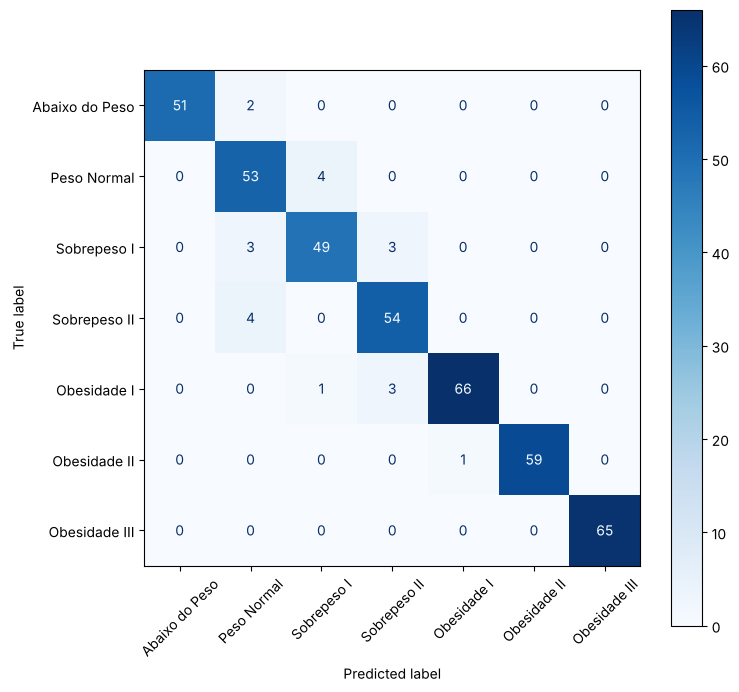

                precision    recall  f1-score   support

Abaixo do Peso       1.00      0.96      0.98        53
   Peso Normal       0.85      0.93      0.89        57
   Sobrepeso I       0.91      0.89      0.90        55
  Sobrepeso II       0.90      0.93      0.92        58
   Obesidade I       0.99      0.94      0.96        70
  Obesidade II       1.00      0.98      0.99        60
 Obesidade III       1.00      1.00      1.00        65

      accuracy                           0.95       418
     macro avg       0.95      0.95      0.95       418
  weighted avg       0.95      0.95      0.95       418



In [75]:
pipe_forest = roda_modelo(RandomForestClassifier(random_state=SEED), X_train, X_test, y_train, y_test)

## 6.5 Gradient Boosting


------------------------------ Resultados GradientBoostingClassifier ------------------------------

Acurácia: 0.9928
AUC (macro, OVR): 0.9999



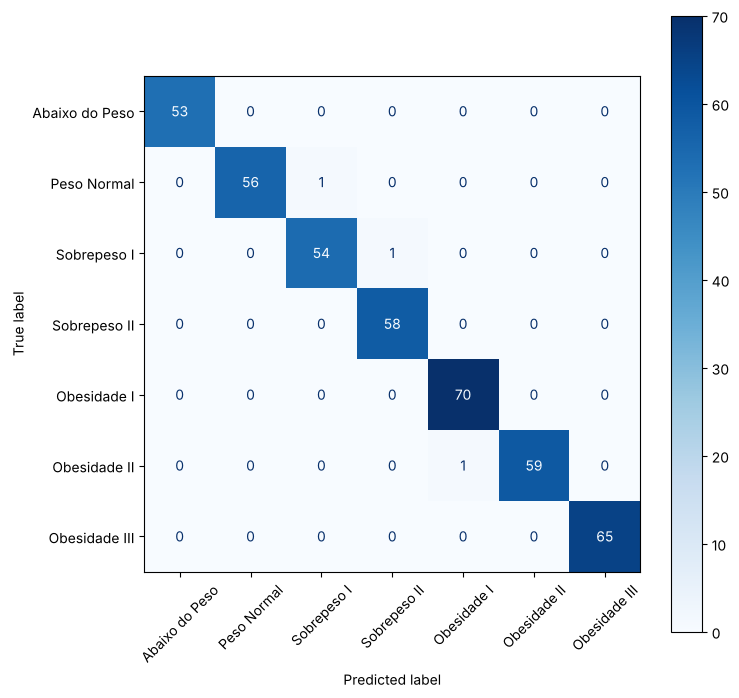

                precision    recall  f1-score   support

Abaixo do Peso       1.00      1.00      1.00        53
   Peso Normal       1.00      0.98      0.99        57
   Sobrepeso I       0.98      0.98      0.98        55
  Sobrepeso II       0.98      1.00      0.99        58
   Obesidade I       0.99      1.00      0.99        70
  Obesidade II       1.00      0.98      0.99        60
 Obesidade III       1.00      1.00      1.00        65

      accuracy                           0.99       418
     macro avg       0.99      0.99      0.99       418
  weighted avg       0.99      0.99      0.99       418



In [76]:
pipe_gb = roda_modelo(GradientBoostingClassifier(random_state=SEED), X_train, X_test, y_train, y_test)

## 6.6 Comparação e escolha do modelo

In [77]:
resultados = pd.DataFrame({
    'Modelo': ['Regressão Logística', 'Árvore de Decisão', 'Random Forest', 'Gradient Boosting'],
    'Acurácia': [accuracy_score(y_test, p.predict(X_test)) for p in [pipe_logistico, pipe_tree, pipe_forest, pipe_gb]]
}).sort_values('Acurácia', ascending=False)
resultados

,Modelo,Acurácia
3,Gradient Boosting,0.992823
2,Random Forest,0.949761
1,Árvore de Decisão,0.935407
0,Regressão Logística,0.708134


## 6.7 Exportando o modelo escolhido

O arquivo salvo contém o pipeline completo (tratamento + modelo), então o app recebe os dados do paciente no mesmo formato da base e não precisa repetir nenhum tratamento.

In [78]:
joblib.dump(pipe_gb, 'modelo.joblib')

['modelo.joblib']

# 7. E sem peso e altura?

O nível de obesidade da base é definido pelo IMC (peso ÷ altura²). Com peso e altura entre as variáveis, o modelo praticamente reaprende essa fórmula, o que explica a acurácia tão alta. Para saber quanto os **hábitos** explicam sozinhos, o mesmo modelo é treinado sem essas duas variáveis.


------------------------------ Resultados GradientBoostingClassifier ------------------------------

Acurácia: 0.7656
AUC (macro, OVR): 0.9527



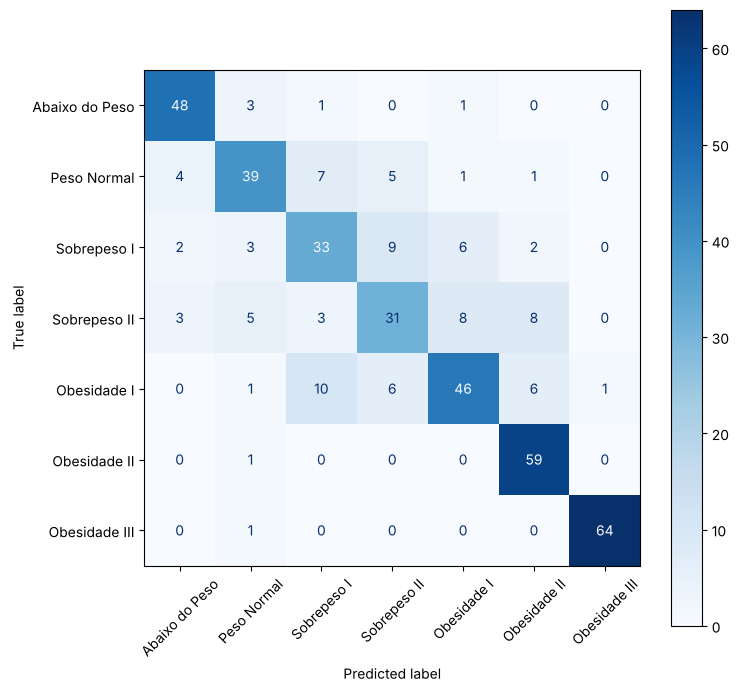

                precision    recall  f1-score   support

Abaixo do Peso       0.84      0.91      0.87        53
   Peso Normal       0.74      0.68      0.71        57
   Sobrepeso I       0.61      0.60      0.61        55
  Sobrepeso II       0.61      0.53      0.57        58
   Obesidade I       0.74      0.66      0.70        70
  Obesidade II       0.78      0.98      0.87        60
 Obesidade III       0.98      0.98      0.98        65

      accuracy                           0.77       418
     macro avg       0.76      0.76      0.76       418
  weighted avg       0.76      0.77      0.76       418



In [79]:
X_train_hab = X_train.drop(columns=['Height', 'Weight'])
X_test_hab = X_test.drop(columns=['Height', 'Weight'])

pipe_habitos = roda_modelo(GradientBoostingClassifier(random_state=SEED), X_train_hab, X_test_hab, y_train, y_test,
                           colunas_min_max=['Age'])

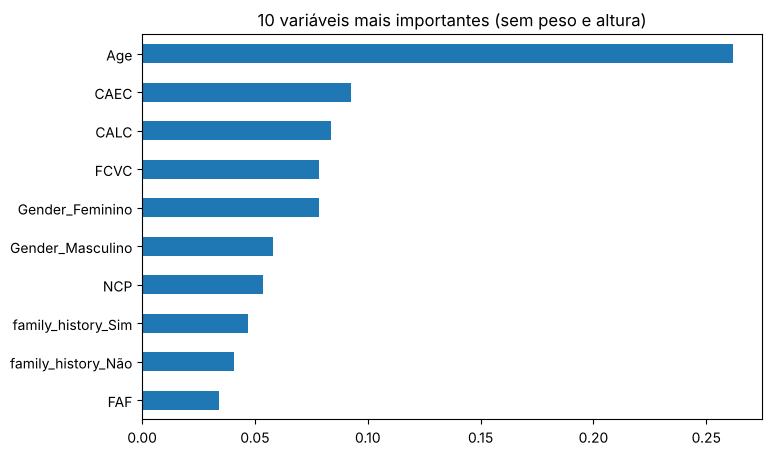

In [80]:
importancias = pd.Series(
    pipe_habitos.named_steps['modelo'].feature_importances_,
    index=pipe_habitos[:-2].transform(X_test_hab.head(1)).columns
).sort_values(ascending=False).head(10)

importancias.sort_values().plot(kind='barh', figsize=(8, 5), title='10 variáveis mais importantes (sem peso e altura)')
plt.show()